# CSE558 Assignment: Question 2 - JL for linear regression (CountSketch)
Group: 2023543, 2023605  
Collaborators / URLs used: *(Used Ai ( GPT and Claude) for understanding and debugging )*

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

SEED = 558                      # every random number below derives from this seed
os.makedirs("figs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Data matrix D and label vector y

In [2]:
kdd = fetch_kddcup99(subset=None, as_frame=True)   # default 10% version
X = kdd.data

# (i) one-hot the 3 text features, convert the other 38 to float
cat_cols = ["protocol_type", "service", "flag"]
def _dec(v):
    return v.decode() if isinstance(v, (bytes, bytearray)) else str(v)
cat = pd.DataFrame({c: X[c].map(_dec) for c in cat_cols})
onehot = pd.get_dummies(cat, dtype=np.float32)
num = X.drop(columns=cat_cols).astype(float).astype(np.float32)
M = pd.concat([num.reset_index(drop=True), onehot.reset_index(drop=True)], axis=1)

# (ii) drop constant columns, (iii) min-max rescale to [0, 1]
Mv = M.to_numpy(dtype=np.float32)
mn, mx = Mv.min(0), Mv.max(0)
keep = mx > mn
print("constant columns dropped:", list(M.columns[~keep]))
D = ((Mv[:, keep] - mn[keep]) / (mx[keep] - mn[keep])).astype(np.float32)
del Mv, M, num, onehot, cat

n, d = D.shape
print(f"n = {n}, d = {d}")
assert D.min() >= 0 and D.max() <= 1

constant columns dropped: ['num_outbound_cmds', 'is_host_login']
n = 494021, d = 116


In [3]:
y = (kdd.target != b"normal.").to_numpy(dtype=float)
assert y.shape[0] == n and 0 < y.mean() < 1
print("fraction of attacks:", y.mean())
D64 = D.astype(np.float64)       # least squares is done in float64

fraction of attacks: 0.8030893423558918


## Helpers

In [4]:
def loss(Dm, yv, a):
    r = Dm @ a - yv
    return float(r @ r)

def draw_cs(n, m, rng):
    """CountSketch hash h(i) in {0..m-1}, sign sigma(i) in {-1,+1}. S itself is never stored."""
    h = rng.integers(0, m, size=n)
    s = rng.choice(np.array([-1.0, 1.0]), size=n)
    return h, s

def apply_cs(Dm, yv, h, s, m, chunk=100_000):
    """One pass over the rows: row i of D is added with sign s[i] to row h[i] of SD."""
    SD = np.zeros((m, Dm.shape[1])); Sy = np.zeros(m)
    for st in range(0, len(Dm), chunk):
        sl = slice(st, st + chunk)
        np.add.at(SD, h[sl], Dm[sl] * s[sl, None])
        np.add.at(Sy, h[sl], s[sl] * yv[sl])
    return SD, Sy

def lstsq(Am, bv):
    return np.linalg.lstsq(Am, bv, rcond=None)

## (a) Full least-squares solution b

In [5]:
t0 = time.perf_counter()
b, _, rank_D, _ = lstsq(D64, y)
time_b = time.perf_counter() - t0
loss_b = loss(D64, y, b)
print(f"Loss(D,y,b) = {loss_b:.6f}")
print(f"time to compute b = {time_b:.3f} s")
print(f"rank(D) as seen by lstsq = {rank_D}  (d = {d})")

Loss(D,y,b) = 2949.788815
time to compute b = 16.638 s
rank(D) as seen by lstsq = 113  (d = 116)


## (b), (c) CountSketch for m = 50 ... 5000
Time in (c) = draw S (h, sigma) + form SD and Sy + solve for a-tilde.

In [14]:
MS = [50, 100, 200, 500, 1000, 2000, 5000]
REPS = 5
rows = []
for m in MS:
    for r in range(REPS):
        rng = np.random.default_rng([SEED, 10, m, r])
        t0 = time.perf_counter()
        h, s = draw_cs(n, m, rng)
        SD, Sy = apply_cs(D64, y, h, s, m)
        at = lstsq(SD, Sy)[0]
        t_run = time.perf_counter() - t0
        L = loss(D64, y, at)
        sk = float(np.sum((SD @ at - Sy) ** 2))
        rows.append(dict(m=m, rep=r, loss=L, ratio=L / loss_b, sketched_loss=sk, time=t_run))
    print("done m =", m)
res2 = pd.DataFrame(rows)
res2.to_csv("tables/q2_runs.csv", index=False)
res2

done m = 50
done m = 100
done m = 200
done m = 500
done m = 1000
done m = 2000
done m = 5000


,m,rep,loss,ratio,sketched_loss,time
0,50,0,7286.645822,2.470226,6.265764e-25,3.039715
1,50,1,8098.232080,2.745360,7.969672e-24,3.898980
2,50,2,8505.596401,2.883459,1.772767e-23,4.501059
3,50,3,11111.134257,3.766756,2.978704e-24,3.022308
4,50,4,9302.392031,3.153579,4.969218e-24,3.062662
5,100,0,42526.838680,14.416910,4.283559e-23,3.846666
6,100,1,83802.094249,28.409523,4.420775e-23,4.570877
7,100,2,22122.541925,7.499704,1.258731e-23,3.078873
8,100,3,79589.644968,26.981472,2.367475e-23,3.062594
9,100,4,50783.008064,17.215811,1.955713e-23,5.358298


In [15]:
summ = res2.groupby("m").agg(loss_mean=("loss", "mean"),
                             ratio_mean=("ratio", "mean"), ratio_min=("ratio", "min"), ratio_max=("ratio", "max"),
                             sketched_mean=("sketched_loss", "mean"), time_mean=("time", "mean"))
summ["Loss(D,y,b)"] = loss_b
summ["time_b"] = time_b
summ["speedup_vs_b"] = time_b / summ["time_mean"]
summ.to_csv("tables/q2_summary.csv")
summ

,loss_mean,ratio_mean,ratio_min,ratio_max,sketched_mean,time_mean,"Loss(D,y,b)",time_b,speedup_vs_b
m,,,,,,,,,
50,8860.800118,3.003876,2.470226,3.766756,6.854369e-24,3.504945,2949.788815,16.637807,4.746953
100,55764.825577,18.904684,7.499704,28.409523,2.857251e-23,3.983462,2949.788815,16.637807,4.176721
200,6500.743591,2.203800,1.826642,2.661324,1.309594e+03,3.646071,2949.788815,16.637807,4.563216
500,3798.682766,1.287781,1.231343,1.352262,2.302310e+03,3.690628,2949.788815,16.637807,4.508124
1000,3302.109605,1.119439,1.108326,1.140680,2.630162e+03,4.323992,2949.788815,16.637807,3.847789
2000,3113.162455,1.055385,1.041311,1.071204,2.703127e+03,4.002748,2949.788815,16.637807,4.156597
5000,3017.022686,1.022793,1.016525,1.032241,2.849442e+03,4.579613,2949.788815,16.637807,3.633016


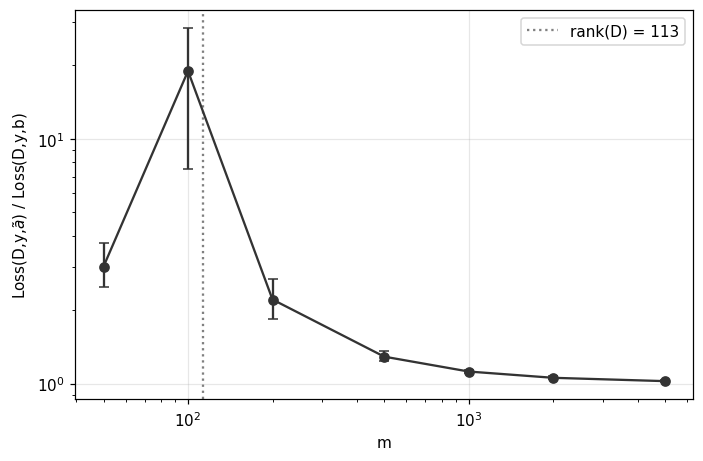

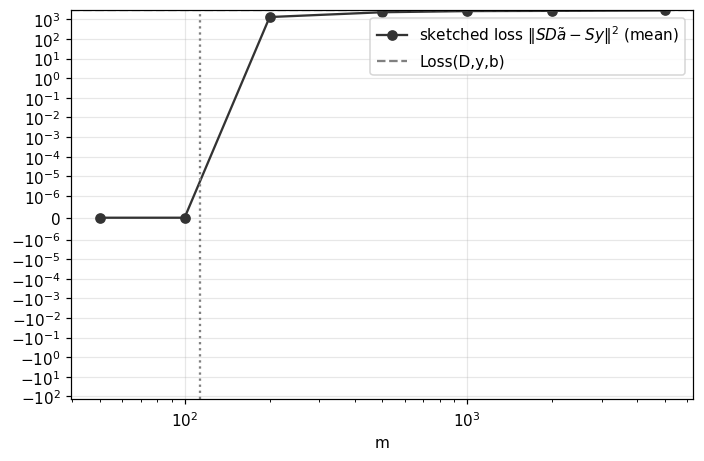

In [16]:
mean = summ["ratio_mean"].values
fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.errorbar(summ.index, mean, yerr=[mean - summ["ratio_min"].values, summ["ratio_max"].values - mean],
            fmt="o-", color="0.2", capsize=3)
ax.axvline(rank_D, color="0.5", ls=":", label=f"rank(D) = {rank_D}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("m"); ax.set_ylabel(r"Loss(D,y,$\tilde a$) / Loss(D,y,b)")
ax.legend(); plt.tight_layout(); plt.savefig("figs/q2_b_ratio.png"); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.plot(summ.index, summ["sketched_mean"], "o-", color="0.2", label=r"sketched loss $\|SD\tilde a-Sy\|^2$ (mean)")
ax.axhline(loss_b, color="0.5", ls="--", label="Loss(D,y,b)")
ax.axvline(rank_D, color="0.5", ls=":")
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1e-6)
ax.set_xlabel("m"); ax.legend(); plt.tight_layout(); plt.savefig("figs/q2_b_sketched.png"); plt.show()


### Comments for (b)

rank(D) came out as 113 while d = 116. The three one-hot groups each sum to 1, which already makes some columns exact combinations of others, so the rank is a bit below d. That puts m = 50 and 100 below the rank and m >= 200 above it.

**Below the rank (m = 50, 100).** The sketched system has fewer equations than the rank, so lstsq can fit it exactly: the sketched loss is about 1e-24, i.e. zero. That says nothing about the real fit. Loss(D, y, a~) is about 3 times the optimum at m = 50 and about 19 times at m = 100, and it varies a lot between runs (7.5 to 28 at m = 100). It is worse at m = 100 than at m = 50, most likely because the sketched system is then nearly square and badly conditioned, so the minimum-norm solution is unstable. This is the usual spike near the interpolation threshold.

**Above the rank (m >= 200).** The sketched loss is no longer zero. It is 1310 at m = 200 and rises to 2849 at m = 5000, creeping up towards Loss(D, y, b) = 2949.8 from below. The true-loss ratio drops quickly (2.2, 1.29, 1.12, 1.06, 1.02 for m

 = 200, 500, 1000, 2000, 5000) and its min-max spread narrows. This matches the usual rules of thumb for sketched least squares with r = 113: ratio about 1 + r/(m - r), and sketched loss about (1 - r/m) times the optimal loss. For m = 500 these predict 1.29 and about 2283, and we observed 1.288 and 2302.


### Comments for (c)

Computing the full least-squares solution took **16.64 seconds**, whereas the average CountSketch-based regression times ranged from approximately **3.50 to 4.58 seconds** across the different sketch dimensions.

This corresponds to a speedup of approximately **3.6–4.7 times**. Although the measured times fluctuate, CountSketch consistently reduces computation time compared with solving the full least-squares problem.

CountSketch avoids constructing a dense random projection matrix by assigning each input row to a randomly selected bucket with a random sign.

Overall, CountSketch offers a useful trade-off between computational efficiency and approximation quality, with larger sketch dimensions generally producing loss ratios closer to 1.

## (d) Norm preservation on the residual v = Db - y

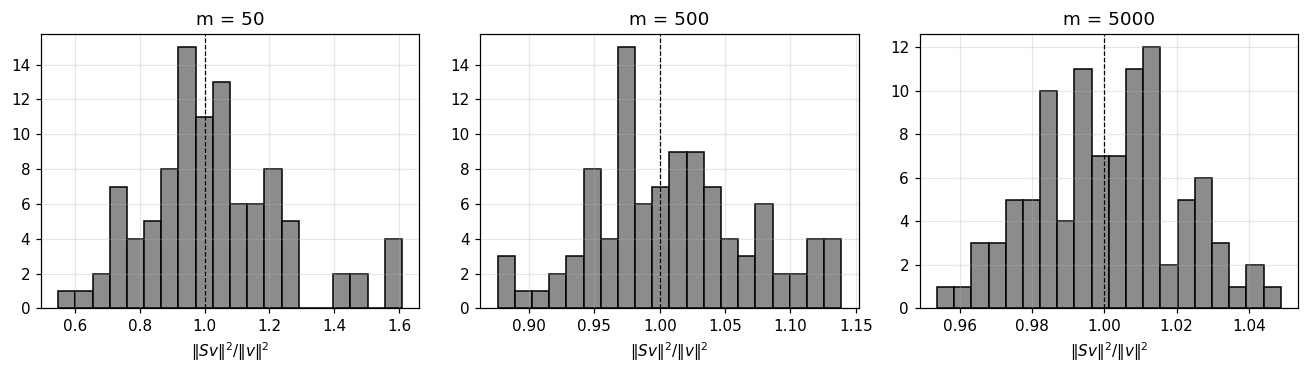

,mean,std
m,,
50,1.027923,0.214640
500,1.010356,0.060689
5000,1.000797,0.019669


In [9]:
v = D64 @ b - y
vn = float(v @ v)
stats = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, m in zip(axes, [50, 500, 5000]):
    out = np.empty(100)
    for t in range(100):
        rng = np.random.default_rng([SEED, 20, m, t])
        h, s = draw_cs(n, m, rng)
        Sv = np.zeros(m); np.add.at(Sv, h, s * v)
        out[t] = (Sv @ Sv) / vn
    stats.append(dict(m=m, mean=out.mean(), std=out.std(ddof=1)))
    ax.hist(out, bins=20, color="0.55", edgecolor="k")
    ax.axvline(1, color="k", ls="--", lw=0.8)
    ax.set_title(f"m = {m}"); ax.set_xlabel(r"$\|Sv\|^2/\|v\|^2$")
plt.tight_layout(); plt.savefig("figs/q2_d_hist.png"); plt.show()
stats = pd.DataFrame(stats).set_index("m"); stats.to_csv("tables/q2_d_stats.csv"); stats


### Comments for (d)

The mean is about 1 (1.028, 1.010, 1.001 for m = 50, 500, 5000), so ||Sv||^2 is an unbiased estimate of ||v||^2. The spread shrinks as m grows: the std is 0.215, 0.061 and 0.0197, very close to sqrt(2/m) = 0.200, 0.063 and 0.020. Making m 100 times bigger makes the std about 10 times smaller, i.e. it scales like 1/sqrt(m). The close match with sqrt(2/m) also suggests the residual is not dominated by a few huge entries.


## (e) CountSketch vs dense Gaussian sketch on a 50,000-row subset (m = 500)

In [10]:
rng_sub = np.random.default_rng([SEED, 30])
sub = rng_sub.choice(n, size=50_000, replace=False)       # fixed subset, used for everything below
Dp, yp = D64[sub], y[sub]
bp = lstsq(Dp, yp)[0]
loss_bp = loss(Dp, yp, bp)
print("Loss(D',y',b') =", loss_bp)

m = 500
res_e = {"CountSketch": [], "Dense Gaussian": []}
for r in range(5):
    # (i) CountSketch
    rng = np.random.default_rng([SEED, 31, r])
    t0 = time.perf_counter()
    h, s = draw_cs(len(Dp), m, rng)
    SD, Sy = apply_cs(Dp, yp, h, s, m)
    t_form = time.perf_counter() - t0
    at = lstsq(SD, Sy)[0]
    res_e["CountSketch"].append((t_form, loss(Dp, yp, at) / loss_bp))
    # (ii) dense S with N(0, 1/m) entries
    rng = np.random.default_rng([SEED, 32, r])
    t0 = time.perf_counter()
    S = rng.normal(0.0, 1.0 / np.sqrt(m), size=(m, len(Dp)))
    SD, Sy = S @ Dp, S @ yp
    t_form = time.perf_counter() - t0
    at = lstsq(SD, Sy)[0]
    res_e["Dense Gaussian"].append((t_form, loss(Dp, yp, at) / loss_bp))
    del S

tab_e = pd.DataFrame({k: {"time to draw S and form SD', Sy' (s)": np.mean([a for a, _ in v]),
                          "Loss ratio (mean of 5)": np.mean([b_ for _, b_ in v]),
                          "Loss ratio (min)": np.min([b_ for _, b_ in v]),
                          "Loss ratio (max)": np.max([b_ for _, b_ in v])}
                      for k, v in res_e.items()}).T
tab_e.to_csv("tables/q2_e.csv"); tab_e

Loss(D',y',b') = 228.91688468759665


,"time to draw S and form SD', Sy' (s)",Loss ratio (mean of 5),Loss ratio (min),Loss ratio (max)
CountSketch,0.367018,1.277117,1.22579,1.321806
Dense Gaussian,1.411258,1.265739,1.22644,1.321318



### Comments for (e)

Both methods produce similar regression accuracy on the fixed 50,000-row subset with \(m = 500\). The average loss ratio is **1.2771 for CountSketch** and **1.2657 for the dense Gaussian sketch**, indicating that the dense method provides only a small improvement in accuracy.

However, CountSketch is considerably faster. Its average sketch construction time is **0.367 seconds**, compared with **1.411 seconds** for the dense Gaussian method, making CountSketch approximately **3.85 times faster**.

The main advantage of CountSketch is that it does not require storing the entire projection matrix. A dense Gaussian projection on the full dataset would require a matrix of size \(500 \times 494021\), occupying approximately 2 GB in float64 representation. CountSketch instead uses random bucket assignments and signs, requiring substantially less memory.

Therefore, **CountSketch is preferable for the full dataset**, as it provides comparable regression accuracy with lower computation time and memory requirements.
